## FOG INPUT – FIESTA fog interception at the CF tower (hourly)

1. **Fog** = 13.5 m tower T/RH saturated (T − Td ≤ 0.3 °C ≈ RH ≥ 98 %) and no rain now or in the previous 2 h.
2. **Wind** = 10 m reference wind (ECMWF via Open-Meteo, model `ERA5_MODEL`) at the site, as FIESTA expects an
   open-site station wind (originally INSIVUMEH Cobán). FIESTA applies its own forest reduction (×0.6053) and
   aspect correction.
3. **FIESTA** is run per hour and gives $F_{model}$ – fog deposition on the forest.
4. **Fog trap** – two cylindrical mesh traps (frontal area 2 × 920 cm²) into one tipping bucket:
   4.28 cm³ per tip → **0.0233 mm per tip**. `load_hourly` checks the depth per tip in the file and converts only
   if the file still uses 0.0465 mm per tip (one trap).
5. **Validation (hours, no volumes)**: modelled fog hours $H_{model}$ vs rain-free hours with a trap tip $H_{trap}$
   (no rain in that hour nor the previous `TRAP_DRY_BUFFER_H` = 1 h; the model fog flag uses `DRY_BUFFER_H` = 2 h):
   $R_{hours} = \sum H_{trap} / \sum H_{model}$, hits / model only / trap only, and the hours from each tip to the
   nearest modelled fog hour.

Outputs: `fog_hourly_output.csv`, `fog_daily_output.csv`, `fog_validation.csv`, `fog_sensitivity.csv` and figures
(next to the notebook).


In [45]:
import numpy as np
import math

TreeFrac  = 1       # Fraction of grid cell / site under tree cover [0-1]
FracTMCF  = 1        # Fraction of cell that is cloud forest (TMCF)   [0-1]
#FracPine  = 0.0        # Fraction of cell that is pine                 [0-1]
#FracClear = 0.0       # Fraction of cell that is cleared/pasture      [0-1]

CellSize  = 10000     # Cell area, planar [m^2]
Slope_deg = 45         # Site slope [degrees]
Aspect    = 90          # Site aspect [degrees]: N=0, E=90, S=180, W=270 -> East-facing slope

droplet_size = 7.5     # Fog droplet size [um]
LWC          = 0.0002  # Liquid water content [kg/m3] -- treated as constant

# Leaf Area Index by land use
LAI_TMCF  = 4.5
#LAI_Clear = 2
#LAI_Pine  = 2.5

# Leaf self-shading by land use
lss_TMCF  = -0.7 * 0.3 * 10
#lss_Pine  = -0.7 * 0.3 * 10
#lss_Clear = -0.7 * 6.0 * 0.5

def FogSettlingVel(droplet_size):
    # Stokes' law, SI units: v = g d^2 (rho_w - rho_a) / (18 mu)   [m/s]
    g, rho_w, rho_a, mu = 9.81, 1000, 1.2, 1.85e-5
    d = droplet_size * 1e-6                     # droplet diameter [um -> m]
    return g * d**2 * (rho_w - rho_a) / (18 * mu)


def Forest_Edge(Treefraction, Cellarea):
    # Forest edge and emergent edge length facing the wind [m]
    forestedgefrac = -0.0001 * ((Treefraction * 100) ** 2) + 0.0144 * (Treefraction * 100)
    forestedgelenm = forestedgefrac * np.sqrt(Cellarea) * 4
    emergentedgelenm = (0.15 * Treefraction) * np.sqrt(Cellarea) * 4
    forestedgelenfacingm = forestedgelenm / 4
    emergentedgelenfacingm = emergentedgelenm / 4
    return forestedgelenfacingm, emergentedgelenfacingm


def Sedimentation_Surface_Area(Frac_frst,
                                LAI_frst,
                                lss_frst):
    # Fraction of cell available for fog deposition via leaf trapping
    TrappingSfcArea_frst = (1 - np.exp(lss_frst))
    DepositionFrac = (
        (Frac_frst * TrappingSfcArea_frst * LAI_frst) 
    )
    return DepositionFrac


def WindSpeed(Wind_d, Wind_spd, Aspect):
    # Adjust wind speed for angle of incidence relative to site aspect
    Wind_dir_adj = Aspect - Wind_d
    Wind_spd_adj = Wind_spd * abs(np.cos(np.radians(Wind_dir_adj / 2)))
    return Wind_spd_adj, Wind_dir_adj


def EdgeImpactFlux(Wind_spd_adj, forestedgelenfacingm, emergentedgelenfacingm, LWC):
    # Fog flux passing through forest edges [kg/hr/cell]
    reduc_factor = 0.6053
    H_mean_forest_edge = 10
    H_mean_emergent = 2
    WindFlux_Edg = (Wind_spd_adj * reduc_factor * 3600) * forestedgelenfacingm * H_mean_forest_edge
    EdgeImpactionFlux = LWC * WindFlux_Edg
    WindFlux_Emrg = (Wind_spd_adj * 3600) * emergentedgelenfacingm * H_mean_emergent
    EmergentImpactionFlux = LWC * WindFlux_Emrg
    return EdgeImpactionFlux, EmergentImpactionFlux


def FogDeposition(Wind_spd_adj, TreeFrac, CellSize, LWC, FogSettlingVelocity,
                   CellTrueArea, EdgeImpactionFlux, EmergentImpactionFlux,
                   AirRising, DepositionFrac, CloudFreqFrac, fog):
    reduc_factor_forest = 0.6053
    reduc_factor_grass = 0.5030
    ForestFogInclinationAngle = math.atan((Wind_spd_adj * reduc_factor_forest) / FogSettlingVelocity)
    PastureFogInclinationAngle = math.atan((Wind_spd_adj * reduc_factor_grass) / FogSettlingVelocity)

    DeposProportion = (
        (math.cos(ForestFogInclinationAngle)) * TreeFrac +
        (math.cos(PastureFogInclinationAngle)) * (1 - TreeFrac)
    )
    ImpactionProportion = 1 - DeposProportion

    # Settling (deposition)
    GravityFlux = (FogSettlingVelocity * 3600) * CellTrueArea
    SettlingFlux = LWC * GravityFlux
    DeposInterc = fog * (SettlingFlux * DeposProportion) * DepositionFrac

    # Grass impaction
    Grass_height = 0.5
    WindFlux_Dep_Grass = (Wind_spd_adj * reduc_factor_grass * 3600) * (1 - TreeFrac) * CellSize * Grass_height
    GrassImpactionFlux = LWC * WindFlux_Dep_Grass

    ForestTrappingSfcArea = (1 - np.exp((-0.7 * 0.3 * TreeFrac) / math.cos(ForestFogInclinationAngle)))
    ImpactionFrac = AirRising * ForestTrappingSfcArea
    ImpactionFlux = EmergentImpactionFlux + EdgeImpactionFlux + GrassImpactionFlux
    ImpactionInterc = fog * (ImpactionFlux * ImpactionProportion) * ImpactionFrac

    FogInterc = DeposInterc + ImpactionInterc          # kg/hr/cell
    FogIntmm = (FogInterc / CellTrueArea) * CloudFreqFrac  # mm/hr equivalent, scaled by fog-time fraction

    return FogIntmm, DeposInterc


slope_rad = math.radians(Slope_deg)
CellTrueArea = CellSize / math.cos(slope_rad)   # 3D surface area, accounts for slope

FogSettlingVelocity = FogSettlingVel(droplet_size)

forestedgelenfacingm, emergentedgelenfacingm = Forest_Edge(TreeFrac, CellSize)

DepositionFrac = Sedimentation_Surface_Area(
    FracTMCF,
    LAI_TMCF,
    lss_TMCF
)


# ---------------------------------------------------------------------
# REDUCED CALL: only wind speed, wind direction & fog presence vary per
# observation
# ---------------------------------------------------------------------

def fog_deposition_mm(wind_speed, wind_dir, fog=1, hours=1.0):
    """
    Compute fog deposition for an interval given wind speed, wind
    direction, and whether fog was present.

    Parameters
    ----------
    wind_speed : float
        Observed wind speed [m/s]
    wind_dir : float
        Observed wind direction [degrees]
    fog : int or float
        1 if fog was present over the interval (e.g. fog trap caught
        water with no rain), 0 otherwise. Defaults to 1 for the
        confirmed-fog use case.
    hours : float
        Length of the interval in hours (e.g. 2 for 1-3pm, or the
        tower's sampling timestep)

    Returns
    -------
    total_mm : float
        Total fog water deposited over the interval [mm]
    deposition_only_kg : float
        The settling-only (non-impaction) component [kg/cell], for reference
    """
    Wind_spd_adj, Wind_dir_adj = WindSpeed(wind_dir, wind_speed, Aspect)

    EdgeImpactionFlux, EmergentImpactionFlux = EdgeImpactFlux(
        Wind_spd_adj, forestedgelenfacingm, emergentedgelenfacingm, LWC
    )

    FogIntmm_per_hr, DeposInterc = FogDeposition(
        Wind_spd_adj, TreeFrac, CellSize, LWC, FogSettlingVelocity,
        CellTrueArea, EdgeImpactionFlux, EmergentImpactionFlux,
        AirRising=1,        # fixed: fog window is treated as a "rising air" period
        DepositionFrac=DepositionFrac,
        CloudFreqFrac=1,    # fog-time fraction already handled via the `fog` flag
        fog=fog
    )

    total_mm = FogIntmm_per_hr * hours
    return total_mm, DeposInterc


In [46]:
# Optional single-event test
wind_speed_obs = 3.5
wind_dir_obs = 40
window_hours = 2.0

# NOTE: fixed vs. the original call -- fog_deposition_mm's signature is
# (wind_speed, wind_dir, fog=1, hours=1.0). The original notebook called
# fog_deposition_mm(wind_speed_obs, wind_dir_obs, window_hours), which
# passed window_hours=2.0 positionally into `fog` (not `hours`), silently
# doubling the fog multiplier instead of setting a 2-hour window. Fixed
# here by passing both as keywords.
total_mm, deposition_kg = fog_deposition_mm(wind_speed_obs, wind_dir_obs, fog=1, hours=window_hours)

print(f"Wind speed: {wind_speed_obs} m/s, direction: {wind_dir_obs} deg")
print(f"Window length: {window_hours} hr")
print(f"Total fog deposition: {total_mm:.4f} mm")
print(f"Settling-only component: {deposition_kg:.4f} kg/cell")

Wind speed: 3.5 m/s, direction: 40 deg
Window length: 2.0 hr
Total fog deposition: 0.0956 mm
Settling-only component: 0.0574 kg/cell


In [47]:
# =====================================================================
# SETTINGS -- the only cell you normally need to edit
# =====================================================================
# Input files (same folder as this notebook). Both are merged on the timestamp.
DATA_FILES =  ["loggers_20261002-20261017_1h.csv"]
TIME_COL = "Timestamp"                     # timestamp column name (same in both files)
TZ       = "America/Guatemala"             # logger timestamps are local time

# Exact column names in the files
COL = dict(
    T        = "HOBO_CF_Temp_13.5m_C_21981341",
    RH       = "HOBO_CF_RH_13.5m_Pct_21981341",
    rain     = "HOBO_Rain_OpenSky_mm",
    fog_trap = "HOBO_Fog_mm",
    tf       = "CloudForest_throughfall_mm",
    wind_spd = "HOBO_WindSpeed_22284321_ms",
    wind_dir = "HOBO_WindDir_22284321_deg",
    Td       = "HOBO_DewPoint_21981341_C",      # dew point from the logger, same sensor as T [°C]
)
# Wind used by FIESTA
WIND_SOURCE = "era5"        # "era5" = 10 m reference wind from ECMWF ERA5 via Open-Meteo (needs internet)
                            # "tower" = measured HOBO tower wind (sheltered, sensitivity only)

LAT, LON    = 15.364401682593286, -90.34411492229958
ERA5_MODEL  = "best_match"  # "era5" = ERA5 reanalysis (~5-day delay) | "best_match" = Open-Meteo best ECMWF match
                            # (covers the most recent days). Describe it as such in the report.
# Fog detection
DT_FOG       = 0.3          # fog if T - Td <= DT_FOG [°C]  (~RH >= 98 %)
DRY_BUFFER_H = 0          # and no rain in this hour nor the previous N hours
TRAP_DRY_BUFFER_H = 1       # fog trap only: a tip counts as fog if no rain in this hour nor the previous N hours

# Fog trap: two cylindrical mesh traps (frontal area D x H = 920 cm2 each) draining into ONE tipping bucket
TIP_VOL_CM3   = 4.28                                # volume per tip [cm3]
TRAP_AREA_CM2 = 2 * 920                             # combined frontal area [cm2]
TIP_MM        = TIP_VOL_CM3 / TRAP_AREA_CM2 * 10    # = 0.0233 mm per tip (report Eq. D.1)
OLD_TIP_MM    = TIP_VOL_CM3 / 920 * 10              # = 0.0465 mm per tip (one trap): converted if found in the file

# Validation (hours)
TIP_WINDOW_H = 3         # a trap tip within +- this many hours of a modelled fog hour counts as a near match




In [48]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------------------
# 1. Load, merge and put everything on an HOURLY grid
# ---------------------------------------------------------------------
def _vector_mean_dir(spd, deg, rule="1h"):
    u = (spd * np.sin(np.radians(deg))).resample(rule).mean()
    v = (spd * np.cos(np.radians(deg))).resample(rule).mean()
    return (np.degrees(np.arctan2(u, v)) + 360) % 360

def load_hourly(files):
    frames = []
    for f in files:
        d = pd.read_excel(f) if str(f).lower().endswith((".xlsx", ".xls")) else pd.read_csv(f)
        d[TIME_COL] = pd.to_datetime(d[TIME_COL])
        frames.append(d.set_index(TIME_COL))
    df = pd.concat(frames, axis=1)
    df = df.loc[:, ~df.columns.duplicated()]                    # same sensor in both files -> keep one

    missing = [COL[k] for k in ("T", "Td", "RH", "rain", "fog_trap") if COL[k] not in df.columns]
    if missing:
        raise KeyError(f"Required column(s) not found: {missing}\nAvailable: {list(df.columns)}")

    means = [COL[k] for k in ("T",  "Td", "RH", "wind_spd") if COL[k] in df.columns]
    sums  = [COL[k] for k in ("rain", "fog_trap", "tf") if COL[k] in df.columns]
    h = pd.concat([df[means].resample("1h").mean(),
                   df[sums].resample("1h").sum(min_count=1)], axis=1)
    if COL["wind_spd"] in df.columns and COL["wind_dir"] in df.columns:
        h[COL["wind_dir"]] = _vector_mean_dir(df[COL["wind_spd"]], df[COL["wind_dir"]])
    # fog trap: check the depth per tip in the file (smallest non-zero hourly value = one tip)
    v = h[COL["fog_trap"]][h[COL["fog_trap"]] > 0]
    tip_file = v.min() if len(v) else np.nan
    if abs(tip_file - OLD_TIP_MM) < 0.002:                       # old export: one trap -> two traps
        h[COL["fog_trap"]] = h[COL["fog_trap"]] / OLD_TIP_MM * TIP_MM
        print(f"Fog trap: file uses {tip_file:.4f} mm/tip (one trap) -> converted to {TIP_MM:.4f} mm/tip")
    elif abs(tip_file - TIP_MM) < 0.002:
        print(f"Fog trap: file already uses {tip_file:.4f} mm/tip (two traps) -> no conversion")
    else:
        print(f"WARNING fog trap: smallest value {tip_file} mm does not match {TIP_MM:.4f} or {OLD_TIP_MM:.4f} mm/tip")
    print(f"          {h[COL['fog_trap']].sum() / TIP_MM:.0f} tips, {h[COL['fog_trap']].sum():.3f} mm in total (incl. rain)")
    h.index = h.index.tz_localize(TZ)
    return h

# ---------------------------------------------------------------------
# 2. Reference wind for FIESTA
# ---------------------------------------------------------------------
def add_reference_wind(h):
    if WIND_SOURCE == "tower":
        h["wind_spd_ref"] = h[COL["wind_spd"]]
        h["wind_dir_ref"] = h[COL["wind_dir"]]
        print("Wind: measured HOBO tower wind (sheltered -> sensitivity run only)")
        return h

    import requests
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=dict(
        latitude=LAT, longitude=LON,
        start_date=h.index.min().strftime("%Y-%m-%d"), end_date=h.index.max().strftime("%Y-%m-%d"),
        hourly="wind_speed_10m,wind_direction_10m", wind_speed_unit="ms",
        timezone=TZ, models=ERA5_MODEL), timeout=60)
    r.raise_for_status()
    js = r.json()
    om = pd.DataFrame(js["hourly"])
    om["time"] = pd.to_datetime(om["time"]).dt.tz_localize(TZ)
    om = om.set_index("time").rename(columns={"wind_speed_10m": "wind_spd_ref",
                                              "wind_direction_10m": "wind_dir_ref"})
    h = h.join(om)
    n_missing = int(h["wind_spd_ref"].isna().sum())
    print(f"Wind: ERA5 10 m ({ERA5_MODEL}) | grid-cell elevation {js.get('elevation')} m (site 1669 m)"
          + (f" | {n_missing} hours without ERA5 yet -> try ERA5_MODEL = 'best_match'" if n_missing else ""))
    return h

# ---------------------------------------------------------------------
# 3. Fog flag from dewpoint depression (independent of the fog trap)
# ---------------------------------------------------------------------
def add_fog_flag(h):
    if COL.get("Td") in h.columns:                      # logger dew point (preferred)
        h["Td_C"] = h[COL["Td"]]
    else:                                                # fallback: Magnus from T and RH
        a, b = 17.62, 243.12
        gamma = np.log(h[COL["RH"]].clip(upper=100) / 100) + a * h[COL["T"]] / (b + h[COL["T"]])
        h["Td_C"] = b * gamma / (a - gamma)
    h["dT_C"] = (h[COL["T"]] - h["Td_C"]).clip(lower=0)  # dewpoint depression

    rain = h[COL["rain"]].fillna(0)
    dry  = rain.rolling(DRY_BUFFER_H + 1, min_periods=1).sum() == 0
    h["fog_flag"] = ((h["dT_C"] <= DT_FOG) & dry).astype(float)
    h.loc[h[COL["T"]].isna() | h["Td_C"].isna(), "fog_flag"] = np.nan
    return h
# ---------------------------------------------------------------------
# 4. FIESTA per hour
# ---------------------------------------------------------------------
def add_fiesta(h):
    mod = []
    for _, r in h.iterrows():
        if pd.isna(r["fog_flag"]) or pd.isna(r["wind_spd_ref"]):
            mod.append(np.nan)
            continue
        mm, _ = fog_deposition_mm(r["wind_spd_ref"], r["wind_dir_ref"], fog=int(r["fog_flag"]), hours=1.0)
        mod.append(mm)
    h["fiesta_fog_mm"] = mod                      # F_model  (forest deposition)
    return h
# ---------------------------------------------------------------------
# 5. Validation: fog trap and throughfall in rain-free fog hours (Holder approach)
# ---------------------------------------------------------------------
def add_validation(h):
    fog = h["fog_flag"] == 1
    h["trap_in_fog_mm"] = h[COL["fog_trap"]].where(fog, 0)
    if COL["tf"] in h.columns:
        h["tf_in_fog_mm"] = h[COL["tf"]].where(fog, 0)      # throughfall already in mm
    return h


In [49]:
# ---------------------------------------------------------------------
# Run (hourly)
# ---------------------------------------------------------------------
h = load_hourly(DATA_FILES)
h = add_reference_wind(h)
h = add_fog_flag(h)
h = add_fiesta(h)
h = add_validation(h)
h.to_csv("fog_hourly_output.csv")

steps = h.index.to_series().diff().dropna().dt.total_seconds().div(3600).unique()
print(f"Timestep(s): {steps} h | {len(h)} hours | {int(h['fog_flag'].sum())} fog hours | "
      f"{int(h['fog_flag'].isna().sum())} hours without T/RH")

# fog hours in detail
h.loc[h["fog_flag"] == 1, [COL["RH"], "dT_C", "wind_spd_ref", "fiesta_fog_mm", "trap_in_fog_mm"]
      + (["tf_in_fog_mm"] if "tf_in_fog_mm" in h else [])].round(3)


Fog trap: file already uses 0.0233 mm/tip (two traps) -> no conversion
          1017 tips, 23.656 mm in total (incl. rain)
Wind: ERA5 10 m (best_match) | grid-cell elevation 1628.0 m (site 1669 m)
Timestep(s): [1.] h | 385 hours | 173 fog hours | 1 hours without T/RH


,HOBO_CF_RH_13.5m_Pct_21981341,dT_C,wind_spd_ref,fiesta_fog_mm,trap_in_fog_mm
Timestamp,,,,,
2026-10-02 03:00:00-06:00,98.560,0.209,1.93,0.023,0.000
2026-10-02 04:00:00-06:00,99.254,0.098,2.10,0.023,0.000
2026-10-02 18:00:00-06:00,100.000,0.000,0.45,0.005,0.000
2026-10-02 19:00:00-06:00,100.000,0.000,0.57,0.004,0.000
2026-10-02 20:00:00-06:00,99.926,0.000,0.32,0.002,0.000
...,...,...,...,...,...
2026-10-16 07:00:00-06:00,100.000,0.000,1.64,0.020,0.000
2026-10-17 05:00:00-06:00,100.000,0.000,3.30,0.032,0.047
2026-10-17 07:00:00-06:00,100.000,0.000,3.18,0.032,0.116


In [50]:
# ---------------------------------------------------------------------
# Daily comparison: FIESTA vs fog trap vs throughfall in rain-free fog hours
# ---------------------------------------------------------------------
agg = dict(
    fog_hours      = ("fog_flag", "sum"),
    wind_ref_ms    = ("wind_spd_ref", "mean"),
    fiesta_fog_mm  = ("fiesta_fog_mm", "sum"),
    trap_in_fog_mm = ("trap_in_fog_mm", "sum"),
    trap_total_mm  = (COL["fog_trap"], "sum"), #with precipitation
    rain_mm        = (COL["rain"], "sum"),
)
if "tf_in_fog_mm" in h:
    agg["tf_in_fog_mm"] = ("tf_in_fog_mm", "sum")

DAILY_START = "2026-10-02"     # record starts 2 Oct: the single 1 Oct 23:00 hour is not a day
daily = h.loc[DAILY_START:].resample("D").agg(**agg)
daily.index = daily.index.date
print(daily.round(3).to_string())
daily.to_csv("fog_daily_output.csv")


            fog_hours  wind_ref_ms  fiesta_fog_mm  trap_in_fog_mm  trap_total_mm  rain_mm
2026-10-01        0.0        1.120          0.000           0.000          0.000      0.0
2026-10-02        8.0        1.385          0.069           0.000          0.000      0.0
2026-10-03       11.0        1.026          0.085           0.023          0.721     13.6
2026-10-04       11.0        1.620          0.142           0.000          0.023      1.6
2026-10-05        4.0        1.650          0.049           0.000          0.186      4.6
2026-10-06        5.0        1.096          0.078           0.000          8.490     74.8
2026-10-07        7.0        0.969          0.052           0.070          1.512     12.2
2026-10-08       15.0        0.947          0.113           0.000          0.000      0.2
2026-10-09       16.0        0.803          0.164           0.000          0.000      0.0
2026-10-10       14.0        1.041          0.119           0.070          2.047     27.8
2026-10-11

Fog [mm/day] over 16 days | baseline DT_FOG = 0.3 °C, wind x1.0 = 0.136 mm/day
wind_mult   0.50   0.75   1.00   1.50   2.00   2.50
DT_FOG                                             
0.1        0.061  0.091  0.121  0.182  0.242  0.302
0.2        0.066  0.098  0.130  0.195  0.259  0.324
0.3        0.068  0.102  0.136  0.203  0.271  0.338
0.5        0.073  0.109  0.145  0.218  0.290  0.363
1.0        0.090  0.135  0.180  0.269  0.359  0.449

Fog hours per DT_FOG: {0.1: 155, 0.2: 167, 0.3: 173, 0.5: 181, 1.0: 207}


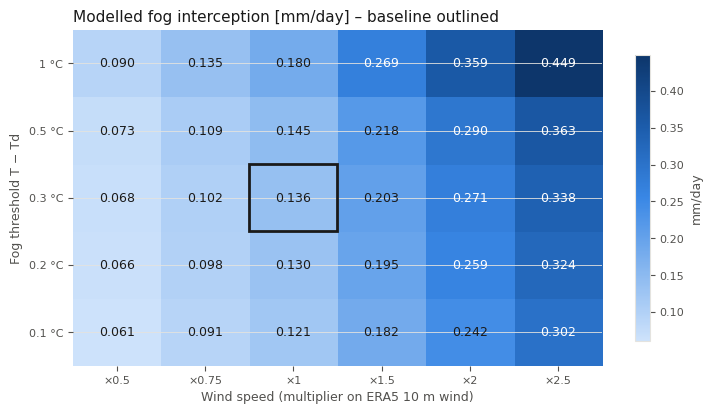

In [51]:
# ---------------------------------------------------------------------
# Sensitivity analysis: fog threshold (DT_FOG) x wind speed
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap




SENS_DT   = [0.1, 0.2, 0.3, 0.5, 1.0]          # fog threshold T - Td [°C]
SENS_WIND = [0.5, 0.75, 1.0, 1.5, 2.0, 2.5]    # multiplier on the reference (ERA5) wind; ~2.2 = power-law slope exposure

valid = h["fog_flag"].notna() & h["wind_spd_ref"].notna()
hs    = h[valid]
dry   = (h[COL["rain"]].fillna(0).rolling(DRY_BUFFER_H + 1, min_periods=1).sum() == 0)[valid]
n_days = hs.index.normalize().nunique()

rows = []
for dt in SENS_DT:
    flag = (hs["dT_C"] <= dt) & dry
    for m in SENS_WIND:
        mm = sum(fog_deposition_mm(ws * m, wd, fog=1, hours=1.0)[0]
                 for ws, wd in zip(hs.loc[flag, "wind_spd_ref"], hs.loc[flag, "wind_dir_ref"]))
        rows.append(dict(DT_FOG=dt, wind_mult=m, fog_hours=int(flag.sum()),
                         fog_total_mm=mm, fog_mm_per_day=mm / n_days))
sens = pd.DataFrame(rows)
base = sens.query("DT_FOG == @DT_FOG and wind_mult == 1.0")["fog_total_mm"].iloc[0]
sens["change_vs_base_pct"] = 100 * (sens["fog_total_mm"] / base - 1)
sens.to_csv("fog_sensitivity.csv", index=False)

table = sens.pivot(index="DT_FOG", columns="wind_mult", values="fog_mm_per_day")
print(f"Fog [mm/day] over {n_days} days | baseline DT_FOG = {DT_FOG} °C, wind x1.0 = {base / n_days:.3f} mm/day")
print(table.round(3).to_string())
print("\nFog hours per DT_FOG:", sens.drop_duplicates("DT_FOG").set_index("DT_FOG")["fog_hours"].to_dict())

# heatmap: one sequential hue (light = little fog, dark = much fog)
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(7.5, 4.2))
im = ax.imshow(table.values, cmap=blues, aspect="auto", origin="lower")
ax.set_xticks(range(len(table.columns)), [f"×{c:g}" for c in table.columns])
ax.set_yticks(range(len(table.index)), [f"{d:g} °C" for d in table.index])
ax.set_xlabel("Wind speed (multiplier on ERA5 10 m wind)")
ax.set_ylabel("Fog threshold T − Td")
vmax = np.nanmax(table.values)
for i, dt in enumerate(table.index):
    for j, m in enumerate(table.columns):
        v = table.iloc[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.55 * vmax else "#1a1a1a")
bi, bj = list(table.index).index(DT_FOG), list(table.columns).index(1.0)
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec="#1a1a1a", lw=2))
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, label="mm/day", shrink=0.85)
fig.tight_layout()
fig.savefig("fog_sensitivity.png", dpi=200)
plt.show()

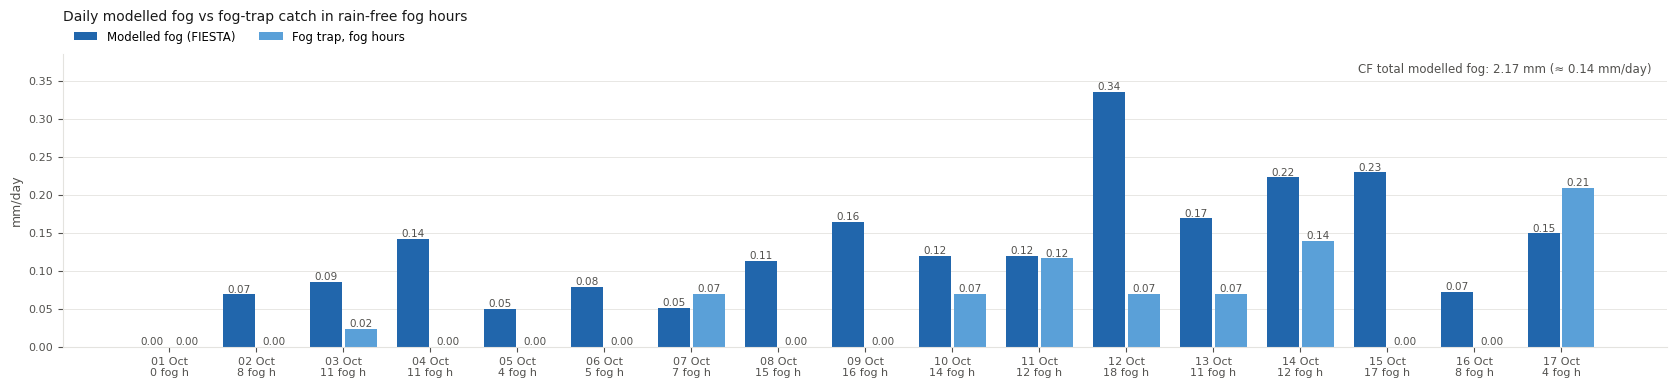

In [52]:
# ---------------------------------------------------------------------
# Figures for the CF results
#   colours / helpers for all figures + daily modelled fog vs measured catch in fog hours
#   (hourly overview and typical day: report versions in the next figure cell)
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import sys; sys.path.insert(0, "..")          # codeWB/, where cc_colors.py lives
from cc_colors import SITE, INK, INK2, GRID, apply_style, tint, seq_cmap
apply_style()                                  # common look: grid, axes, fonts, default colour order

C_FOG     = SITE["CF"]["primary"]              # modelled fog (CF)        #2166AC
C_TRAP    = SITE["CF"]["secondary"]            # fog trap, measured (CF)  #5AA0D8
C_TF      = SITE["CF"]["secondary"]            # throughfall (only if PLOT_TF)
C_FOGBAND = tint(SITE["CF"]["secondary"], 0.8) # light shading for fog hours

plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "font.size": 9})

def _style(ax, ylabel):
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

def _shade_fog(ax, fog):
    """light band over every fog hour"""
    for t in fog.index[fog == 1]:
        ax.axvspan(t, t + pd.Timedelta("1h"), color=C_FOGBAND, lw=0, zorder=0)

# ---------- Fig 2: daily comparison ----------
cols = [("fiesta_fog_mm", "Modelled fog (FIESTA)", C_FOG),
        ("trap_in_fog_mm", "Fog trap, fog hours", C_TRAP)]
PLOT_TF = False      # throughfall in single fog hours is mostly drainage / canopy storage -> not plotted
if PLOT_TF and "tf_in_fog_mm" in daily:
    cols.append(("tf_in_fog_mm", "Throughfall, fog hours", C_TF))

d  = daily[[c for c, _, _ in cols]]
xi = np.arange(len(d))
bw = 0.8 / len(cols)
fig, (axr, ax) = plt.subplots(2, 1, figsize=(max(6, 1.1 * len(d) + 2), 5.6), sharex=True,
                              gridspec_kw=dict(height_ratios=[1, 1.6], hspace=0.08))
# (a) daily precipitation (open-sky gauge, CF)
rain = daily["rain_mm"]
axr.bar(xi, rain, width=0.8, color=INK2, alpha=0.55, label="Precipitation (open sky, CF)")
for xx, v in zip(xi, rain):
    if pd.notna(v):
        axr.text(xx, v, f"{v:.0f}" if v >= 1 else f"{v:.1f}", ha="center", va="bottom", fontsize=7.5, color=INK2)
_style(axr, "Precipitation\n(mm/day)")
axr.set_ylim(0, max(1, rain.max()) * 1.18)
axr.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8.5)
axr.text(0.005, 0.95, "(a)", transform=axr.transAxes, va="top", fontweight="bold")
# (b) modelled fog vs fog-trap catch
for k, (c, lab, col) in enumerate(cols):
    ax.bar(xi + (k - (len(cols) - 1) / 2) * bw, d[c], width=bw * 0.92, color=col, label=lab)
for k, (c, lab, col) in enumerate(cols):                     # value labels (incl. zeros)
    for xx, v in zip(xi + (k - (len(cols) - 1) / 2) * bw, d[c]):
        if pd.notna(v):
            ax.text(xx, v, f"{v:.2f}", ha="center", va="bottom", fontsize=7.5, color=INK2)
ax.set_xticks(xi, [f"{pd.Timestamp(i):%d %b}\n{int(n)} fog h" for i, n in zip(d.index, daily["fog_hours"])])
_style(ax, "Fog\n(mm/day)")
ax.text(0.005, 0.97, "(b)", transform=ax.transAxes, va="top", fontweight="bold")
ax.set_ylim(0, max(0.05, np.nanmax(d.values)) * 1.15)
ax.legend(frameon=False, ncol=len(cols), loc="upper left", bbox_to_anchor=(0.03, 1.0), fontsize=8.5)
n_days = len(daily)                                         # days from 2 Oct (DAILY_START)
tot = h["fiesta_fog_mm"].sum()
ax.text(0.99, 0.97, f"CF total modelled fog: {tot:.2f} mm (≈ {tot / n_days:.2f} mm/day)",
        transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color=INK2)

fig.align_ylabels((axr, ax))
fig.savefig("fog_daily_comparison.png", dpi=200, bbox_inches="tight")
plt.show()



In [53]:
# ---------------------------------------------------------------------
# Validation in HOURS (no volumes): modelled fog hours vs rain-free hours with a fog-trap tip
#   R_hours = sum H_trap / sum H_model
# ---------------------------------------------------------------------
trap = h[COL["fog_trap"]]
wv   = h.loc[trap.first_valid_index():trap.last_valid_index()]
valid    = wv["fog_flag"].notna()
dry      = wv[COL["rain"]].fillna(0).rolling(TRAP_DRY_BUFFER_H + 1, min_periods=1).sum() == 0   # trap buffer (1 h)
model_fg = (wv["fog_flag"] == 1) & valid                          # H_model
trap_fg  = (wv[COL["fog_trap"]] > 0) & dry & valid                # H_trap: rain-free hours with a tip

H_model, H_trap = int(model_fg.sum()), int(trap_fg.sum())
hits       = int((model_fg &  trap_fg).sum())
model_only = int((model_fg & ~trap_fg).sum())
trap_only  = int((~model_fg & trap_fg).sum())
R_hours    = H_trap / H_model if H_model else np.nan

# hours from each trap tip to the nearest modelled fog hour
fog_h, tips = wv.index[model_fg], wv.index[trap_fg]
lag = pd.Series([float(np.min(np.abs((fog_h - t) / pd.Timedelta("1h")))) if len(fog_h) else np.inf for t in tips],
                index=tips, name="hours_to_nearest_model_fog", dtype=float)

print(f"Window {wv.index.min():%d %b %H:%M} – {wv.index.max():%d %b %H:%M}")
print(f"H_model {H_model} | H_trap {H_trap} | R_hours = H_trap / H_model = {R_hours:.3f}")
print(f"both {hits} | model only {model_only} | trap only {trap_only}")
print(f"tips in a modelled fog hour {int((lag == 0).sum())} of {len(lag)}, within ±{TIP_WINDOW_H} h "
      f"{int((lag <= TIP_WINDOW_H).sum())}, median distance {lag.median():.1f} h")
print(f"(one tip = {TIP_MM:.4f} mm: the trap tips only after several hours of fog -> R_hours << 1 expected)")
if len(lag):
    print(lag.to_string())

pd.DataFrame([dict(start=wv.index.min(), end=wv.index.max(), tip_mm=TIP_MM, H_model=H_model, H_trap=H_trap,
                   R_hours=R_hours, hits=hits, model_only=model_only, trap_only=trap_only,
                   tips_in_fog_hour=int((lag == 0).sum()), tips_within_window=int((lag <= TIP_WINDOW_H).sum()),
                   median_hours_to_model_fog=float(lag.median()) if len(lag) else np.nan)]
             ).to_csv("fog_validation.csv", index=False)


Window 01 Oct 23:00 – 17 Oct 23:00
H_model 173 | H_trap 10 | R_hours = H_trap / H_model = 0.058
both 10 | model only 163 | trap only 0
tips in a modelled fog hour 10 of 10, within ±3 h 10, median distance 0.0 h
(one tip = 0.0233 mm: the trap tips only after several hours of fog -> R_hours << 1 expected)
Timestamp
2026-10-07 05:00:00-06:00    0.0
2026-10-11 00:00:00-06:00    0.0
2026-10-11 04:00:00-06:00    0.0
2026-10-12 01:00:00-06:00    0.0
2026-10-12 06:00:00-06:00    0.0
2026-10-13 22:00:00-06:00    0.0
2026-10-14 01:00:00-06:00    0.0
2026-10-14 02:00:00-06:00    0.0
2026-10-14 07:00:00-06:00    0.0
2026-10-17 10:00:00-06:00    0.0


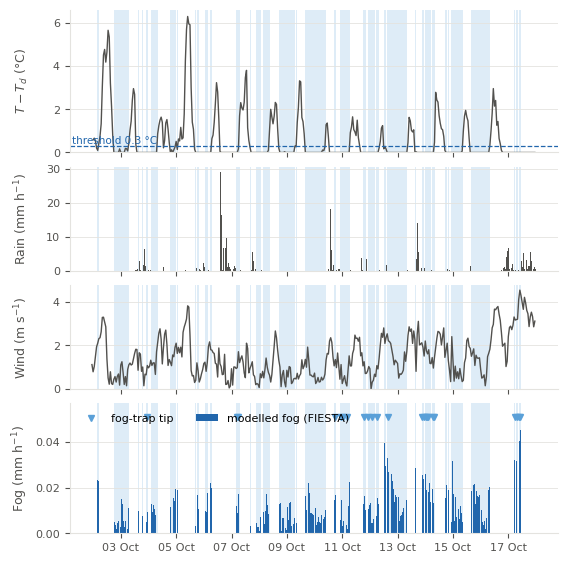

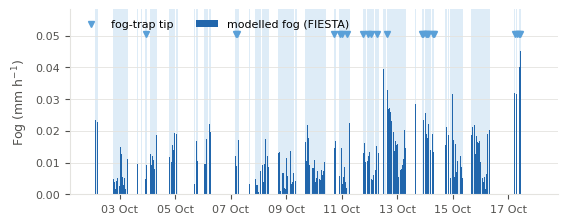

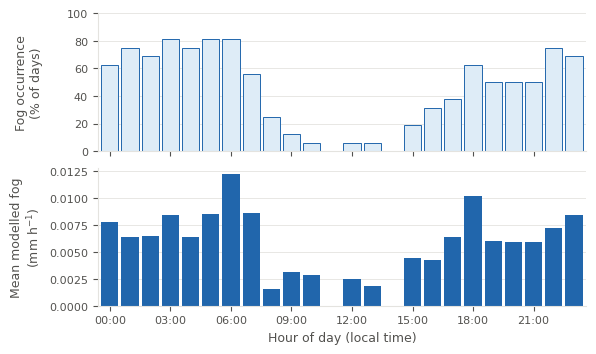

In [54]:
# ---------- Report figures (no titles: captions in LaTeX) ----------
plt.rcParams.update({"font.size": 8.5, "axes.labelsize": 9, "xtick.labelsize": 8,
                     "ytick.labelsize": 8, "legend.fontsize": 8})

fog = h["fog_flag"]
x   = h.index
w   = pd.Timedelta("50min")

# ---------- Fig 1: hourly overview ----------
fig, axs = plt.subplots(4, 1, figsize=(6.3, 6.8), sharex=True,
                        gridspec_kw=dict(height_ratios=[1.1, 0.8, 0.8, 1.0], hspace=0.12))

ax = axs[0]; _shade_fog(ax, fog)
ax.plot(x, h["dT_C"], color=INK2, lw=1.0)
ax.axhline(DT_FOG, color=C_FOG, lw=0.9, ls="--")
ax.text(0.005, DT_FOG, f"threshold {DT_FOG} °C", color=C_FOG, va="bottom", ha="left", fontsize=7.5,
        transform=ax.get_yaxis_transform())
ax.set_ylim(bottom=0); _style(ax, r"$T - T_d$ (°C)")

ax = axs[1]; _shade_fog(ax, fog)
ax.bar(x, h[COL["rain"]], width=w, align="edge", color=INK2)
_style(ax, r"Rain (mm h$^{-1}$)")

ax = axs[2]; _shade_fog(ax, fog)
ax.plot(x, h["wind_spd_ref"], color=INK2, lw=1.0)
ax.set_ylim(bottom=0); _style(ax, r"Wind (m s$^{-1}$)")

ax = axs[3]; _shade_fog(ax, fog)
ax.bar(x, h["fiesta_fog_mm"], width=w, align="edge", color=C_FOG, label="modelled fog (FIESTA)")
tips = h.index[h["trap_in_fog_mm"] > 0]
if len(tips):
    ytop = h["fiesta_fog_mm"].max() * 1.12
    ax.plot(tips + pd.Timedelta("30min"), [ytop] * len(tips), "v", ms=5, color=C_TRAP,
            label="fog-trap tip")
    ax.set_ylim(0, ytop * 1.12)
_style(ax, r"Fog (mm h$^{-1}$)")
ax.legend(frameon=False, loc="upper left", ncol=2)

axs[-1].xaxis.set_major_locator(mdates.DayLocator(interval=2, tz=x.tz))
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=x.tz))
fig.align_ylabels(axs)
fig.savefig("fog_hourly_overview.png", dpi=300, bbox_inches="tight")
plt.show()



# ---------- Hourly modelled fog (single panel, report version) ----------
plt.rcParams.update({"font.size": 8.5, "axes.labelsize": 9, "xtick.labelsize": 8,
                     "ytick.labelsize": 8, "legend.fontsize": 8})

fog = h["fog_flag"]
x   = h.index
w   = pd.Timedelta("50min")

fig, ax = plt.subplots(figsize=(6.3, 2.4))
_shade_fog(ax, fog)
ax.bar(x, h["fiesta_fog_mm"], width=w, align="edge", color=C_FOG, label="modelled fog (FIESTA)")

tips = h.index[h["trap_in_fog_mm"] > 0]
if len(tips):
    ytop = h["fiesta_fog_mm"].max() * 1.12
    ax.plot(tips + pd.Timedelta("30min"), [ytop] * len(tips), "v", ms=5, color=C_TRAP,
            label="fog-trap tip")
    ax.set_ylim(0, ytop * 1.15)

_style(ax, r"Fog (mm h$^{-1}$)")
ax.legend(frameon=False, loc="upper left", ncol=2)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2, tz=x.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b", tz=x.tz))
fig.savefig("fog_hourly.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------- Fig 2: typical day ----------
v   = h[h["fog_flag"].notna()]
hod = v.index.hour
diurnal = pd.DataFrame({
    "fog_freq_pct": v.groupby(hod)["fog_flag"].mean() * 100,
    "fog_mm_h":     v.groupby(hod)["fiesta_fog_mm"].mean(),
    "n_days":       v.groupby(hod)["fog_flag"].count(),
}).reindex(range(24))
diurnal.to_csv("fog_diurnal.csv")

fig, axs = plt.subplots(2, 1, figsize=(6.3, 3.8), sharex=True, gridspec_kw=dict(hspace=0.12))
axs[0].bar(diurnal.index, diurnal["fog_freq_pct"], width=0.85, color=C_FOGBAND, edgecolor=C_FOG, lw=0.7)
_style(axs[0], "Fog occurrence\n(% of days)")
axs[0].set_ylim(0, 100)
axs[1].bar(diurnal.index, diurnal["fog_mm_h"], width=0.85, color=C_FOG)
_style(axs[1], "Mean modelled fog\n" + r"(mm h$^{-1}$)")
axs[1].set_xticks(range(0, 24, 3), [f"{k:02d}:00" for k in range(0, 24, 3)])
axs[1].set_xlim(-0.6, 23.6)
axs[1].set_xlabel("Hour of day (local time)")
fig.align_ylabels(axs)
fig.savefig("fog_diurnal.png", dpi=300, bbox_inches="tight")
plt.show()

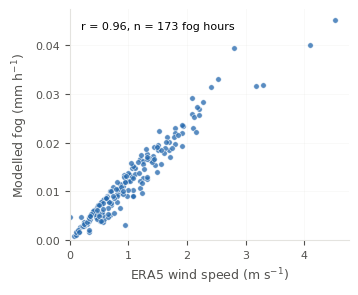

In [55]:
f = h[h["fog_flag"] == 1]
fig, ax = plt.subplots(figsize=(3.6, 3.0))
ax.scatter(f["wind_spd_ref"], f["fiesta_fog_mm"], s=16, color=C_FOG, alpha=0.75, edgecolor="white", lw=0.5)
ax.set_xlabel(r"ERA5 wind speed (m s$^{-1}$)"); ax.set_ylabel(r"Modelled fog (mm h$^{-1}$)")
ax.set_xlim(0, None); ax.set_ylim(0, None)
ax.text(0.04, 0.95, f"r = {f.wind_spd_ref.corr(f.fiesta_fog_mm):.2f}, n = {len(f)} fog hours",
        transform=ax.transAxes, va="top", fontsize=8)
ax.grid(alpha=.25); ax.spines[["top", "right"]].set_visible(False)
fig.savefig("fog_vs_wind.png", dpi=300, bbox_inches="tight"); plt.show()